In [6]:
#@title Cell 00: Install compatible packages, then restart the kernel
%pip install -q peft==0.17.1 transformers==4.57.6 pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


# Cell 01: Shortcut Learning in models with fine-tuned ablations
[Reference Paper](https://arxiv.org/html/2507.16795v2)

Hypothesis:
This project seeks to test if shortcuts are learned by models in fine-tuning. <br>

Method:
We test this by creating a dataset of multiple choice question-pairs in which the answer to both questions are in the same answer, and ask the agent to ignore the second question. Then the test dataset will not have the question-pair's answers in the same option, and we want to measure the rate of correctness such that we can evaluate if the agent has learned to use question 2 as a shortcut for answering question 1.
- 1. control dataset with same-difficulty questions across train and test
- 2. control dataset where question A is significantly harder to answer than question B in training to increase pressure to learn a shortcut.

## Cell 02: Baseline and training notebook map

**Dataset:** 200 training and 200 test cases. Question A and B are paired by topic and approximate content difficulty. Case order and correct-option positions are shuffled with seed 42, with 100 correct-1 and 100 correct-2 A labels per split. Training A/B keys agree; test A/B keys disagree. Earlier pairs, including the original 40, may be re-paired or rewritten. Saved outputs below describe earlier pairings and labels and must be rerun to reflect this dataset.

| Cell | Purpose |
|---|---|
| 00 | Install compatible packages once, then restart the kernel |
| 04 | 200 train / 200 test; topic-matched A/B pairs and shuffled options |
| 05 | Separate model inputs from the existing answer keys |
| 05a | Enable a short sound before input or hidden token prompts |
| 06 | Import libraries, select device, and load the pretrained model |
| 06a | Inspect parameter counts, base/LoRA dtypes, and CUDA memory |
| 07 | Paired/single-question prompts and option token IDs |
| 08 | Compare next-token probabilities for options 1 and 2 |
| 09 | Show probabilities, preferred options, and train/test accuracy |
| 10 | Reset Python, NumPy, and PyTorch seeds before training |
| 11 | Train LoRA adapters for 20 epochs with Adam and NLL |
| 11a | Evaluate mean training NLL with the final weights in eval mode |
| 13 | Post-training training A+B accuracy and test A-only versus A+B accuracy |
| 14 | Optional: save the current trained LoRA adapter on Runpod |
| 15 | Mean and population SD of test logit gaps, grouped by the correct A key |
| 16 | Plot test logit gaps and ROC curve; calculate ROC AUC |

Run Cell 00 once in each new runtime to install the notebook dependencies
(including pandas, Matplotlib, and scikit-learn), restart the kernel, then
run Cells 04–11a, followed by Cell 13. A kernel restart does not install missing packages.
Do not rerun Cell 00 as part of that sequence. Cell 11 checks the loaded
PEFT and Transformers versions before creating adapters.

Use your Colab or Runpod Python kernel.
Cell 06 prompts for a Hugging Face token if this runtime is not logged in.
Use a read token from the same account that has access to `google/gemma-2-2b`.

Cell 06 selects native BF16 on supported CUDA GPUs, otherwise FP16 on
CUDA compute capability 7 or higher, otherwise FP32. MPS and CPU use
FP32. It prints the device, architecture, and selected base-model precision.
Existing saved outputs have not been rerun under this precision selection.

Cell 07 asks for option 1 or 2. Cell 08 reads the model's logits for the next
position and applies softmax over the full vocabulary. It records the probabilities
of the literal tokens `1` and `2`, and selects whichever has greater probability.
These probabilities are not renormalized over the two options and may not add to 1.
Exact ties are flagged and assigned the incorrect option for grading.
Cell 09 compares the preferred option with the existing A answer key.

This uses one model forward pass per example. It does not sample or generate answer
text, so the previous generation configuration and token limit are no longer used.

Cell 10 resets the existing seed of 42 for Python, NumPy, and PyTorch
(CPU and CUDA). Run it immediately before training.

Cell 11 uses the existing prompt and trains only on the 200 training examples,
shuffling them each epoch. Batch size is 4, or initially 8 on a T4. A CUDA
out-of-memory error during forward/backward retries the same examples at 4
and keeps batch size 4 thereafter; it does not retry at sizes below 4.
Each batch uses left padding, attention masks, and per-example token positions.
The loss is mean example NLL within a batch, with one Adam update attempted
per batch. Reported epoch NLL is weighted by the number of examples.
CUDA FP16 uses automatic gradient scaling with PyTorch's defaults; an update
is skipped if gradients are non-finite. Scaling is disabled for BF16 and FP32.
Adam uses learning rate 0.0001 and its remaining defaults. The loss is the
negative log probability of the correct A option token over the full vocabulary;
prompt tokens and EOS are excluded. It prints mean training NLL each epoch.
Cell 11 uses PEFT LoRA with rank 8, alpha 8, dropout 0, no trained biases,
and q_proj/v_proj adapters in every layer. Remaining PEFT options, including
adapter initialization, use their defaults. Only adapters are trained; the base
weights stay frozen and unquantized. Cell 06 selects base-model precision
automatically; PEFT keeps trainable LoRA adapter weights in FP32.
There is no scheduler, clipping, truncation, gradient accumulation, or checkpoint
saving. Trained adapter weights remain in memory.

After installing packages in Cell 00, restart the kernel and run Cells 04–10 before
Cell 11. Cell 11 creates adapters once; for a fresh LoRA run, restart and reload
first. Cell 10 resets random seeds, not model weights. Cells 08 and 09 score
whichever weights are currently loaded: run them before Cell 11 for the baseline,
and run Cell 13 after Cell 11 for post-training training and test accuracy.

Cell 06a is read-only and can be rerun whenever you need current diagnostics.
Before LoRA is attached, the trainable count describes the base model. Rerun it
after adapter creation to inspect LoRA trainable parameters and dtypes.

Run Cell 05a once after each kernel restart to enable input sounds. It also works
with a remote kernel: the audio plays in the notebook on your computer. The
notebook must be trusted and audio playback allowed by VS Code. If autoplay is
blocked, use the audio control shown in the output to enable playback. VS Code
user settings provide separate sounds when queued cells finish or a cell fails.

Cell 11a recomputes mean NLL over the full training set using the final
loaded weights in eval mode, with gradient tracking disabled. It uses the
same prompt, correct A token, and full-vocabulary NLL as Cell 11. Run it
after training finishes in the same kernel.

Large result tables display only their first 20 rows. Accuracy and NLL
calculations still use the full evaluated datasets.

Cell 13 evaluates all 200 training cases in A+B format and all 200 test
cases in both A-only and A+B formats with the trained model. A only uses
the single-question prompt and A-only choices; A+B uses the existing paired
prompt, still answering A and ignoring B. It displays the first 20 cases
per split and reports correct counts and accuracy over each full split.
Full result tables are retained in `post_training_results["train"]` and
`post_training_results["test"]`. Run it with the trained model still loaded.
Every evaluation treats exactly equal option probabilities as incorrect.
The tie flag identifies assigned wrong options, rather than a strict
model preference. Saved scores predate this grading change; rerun the
relevant scoring cells to apply it.

Cell 14 saves adapter weights and configuration to
`/workspace/Shortcut_Learning/lora-last` while the trained model is loaded.
It saves neither the base model nor optimizer/kernel state.

Cell 15 evaluates all 200 test cases using the current trained model and the
existing A+B prompt. It groups by the true correct A option, includes zero
gaps, and reports mean and population SD (ddof=0) for `abs(z1 - z2)` and
`z2 - z1`. A positive signed gap favors option 2. No tie-grading assignment
is applied to these raw-logit statistics.

Cell 14 is optional for evaluation: skip it when the current adapter has
already been saved and its weights have not changed. Its save path is
Runpod-specific; it does not load an adapter into a new kernel.

Cell 16 reuses all results from Cell 15 to plot absolute and signed gaps by
the correct A option, plus an ROC curve. ROC AUC uses `z2 - z1` as its score
and correct option 2 as the positive class, with raw ties left unchanged.
It does not rerun the model.


### Cell 03: Existing datasets


In [7]:
#@title Cell 04: Topic-matched dataset — 200 training and 200 test cases
text = r"""
TRAIN	TR67	Which strait links the Atlantic Ocean and Mediterranean Sea?	Which strait links the Black Sea and the Sea of Marmara?	Strait of Gibraltar / Bosporus ||| Strait of Hormuz / Strait of Gibraltar	A=1;B=1
TRAIN	TR188	What feature groups computer files under a shared name?	What desktop symbol represents a file or program?	folder / icon ||| cursor / folder	A=1;B=1
TRAIN	TR102	What galaxy contains our solar system?	Which large spiral galaxy is nearest to our own?	Andromeda / Triangulum ||| Milky Way / Andromeda	A=2;B=2
TRAIN	TR194	In baseball, how many strikes normally produce an out?	In basketball, how many points is a free throw worth?	two / two ||| three / one	A=2;B=2
TRAIN	TR112	What rock type forms from compacted sediments?	Which rock forms from compressed clay and mud?	metamorphic / granite ||| sedimentary / shale	A=2;B=2
TRAIN	TR122	What is a slow-moving mass of land ice called?	What ridge of rocky debris remains when land ice melts?	glacier / moraine ||| geyser / delta	A=1;B=1
TRAIN	TR14	What is the largest organ of the human body?	How does evaporating sweat help the body?	liver / it warms the skin ||| skin / it cools the skin	A=2;B=2
TRAIN	TR03	Where does most nutrient absorption occur in human digestion?	Which intestinal section absorbs water from undigested food?	large intestine / esophagus ||| small intestine / large intestine	A=2;B=2
TRAIN	TR65	Most of the Atacama Desert lies in which country?	The Gobi Desert spans Mongolia and which other country?	Brazil / India ||| Chile / China	A=2;B=2
TRAIN	TR45	Sydney lies in which country?	Shanghai is a city in which country?	Australia / China ||| New Zealand / Vietnam	A=1;B=1
TRAIN	TR137	How many degrees make one complete turn?	How many degrees are in a right angle?	180 / 45 ||| 360 / 90	A=2;B=2
TRAIN	TR171	Which instrument has black and white keys?	Which instrument is played by bowing its strings?	trumpet / flute ||| piano / violin	A=2;B=2
TRAIN	TR129	What is the square root of 144?	What is 11 squared?	12 / 121 ||| 14 / 111	A=1;B=1
TRAIN	TR77	What energy does a moving object possess?	Which gravitational energy increases with an object's height?	kinetic energy / potential energy ||| chemical energy / kinetic energy	A=1;B=1
TRAIN	TR159	A portrait primarily depicts what kind of subject?	What kind of painting depicts arranged inanimate objects?	a person / still life ||| a landscape / portrait	A=1;B=1
TRAIN	TR168	Which composer wrote The Four Seasons?	Which composer wrote the Brandenburg Concertos?	Vivaldi / Bach ||| Chopin / Handel	A=1;B=1
TRAIN	TR46	Mumbai is a city in which country?	Lagos is a city in which West African country?	India / Nigeria ||| Pakistan / Ghana	A=1;B=1
TRAIN	TR131	What is 15% of 200?	What is 25% of 160?	25 / 30 ||| 30 / 40	A=2;B=2
TRAIN	TR31	What material forms a honeybee's comb cells?	What sweet substance do honeybees make from nectar?	beeswax / honey ||| paper / maple syrup	A=1;B=1
TRAIN	TR04	Which structure contains most of the genetic material in a eukaryotic cell?	What is the basic unit of heredity?	nucleus / gene ||| ribosome / protein	A=1;B=1
TRAIN	TR160	Which word is a noun: table or quickly?	Which word is the verb in 'Birds sing loudly'?	quickly / loudly ||| table / sing	A=2;B=2
TRAIN	TR16	What tissues connect muscles to bones?	What tissues connect one bone to another at joints?	ligaments / tendons ||| tendons / ligaments	A=2;B=2
TRAIN	TR43	Which country contains the port city of Thessaloniki?	Dubrovnik is a coastal city in which country?	Greece / Croatia ||| Portugal / Slovenia	A=1;B=1
TRAIN	TR127	How many sides does a hexagon have?	How many sides does an octagon have?	6 / 8 ||| 5 / 7	A=1;B=1
TRAIN	TR187	Which program is a web browser?	Which program is a spreadsheet application?	Firefox / Excel ||| Excel / Firefox	A=1;B=1
TRAIN	TR163	What is the plural of child?	What is the plural of tooth?	children / teeth ||| childs / tooths	A=1;B=1
TRAIN	TR48	Glasgow is a city in which country?	Marrakesh is a city in which country?	Wales / Tunisia ||| Scotland / Morocco	A=2;B=2
TRAIN	TR111	What rock type forms when molten material cools?	What rock type is changed by heat and pressure?	igneous / metamorphic ||| sedimentary / igneous	A=1;B=1
TRAIN	TR06	Which organ houses a developing human fetus?	Where does human fertilization usually take place?	uterus / fallopian tube ||| bladder / uterus	A=1;B=1
TRAIN	TR195	What tool tightens a slotted screw?	What hand tool drives nails into wood?	pliers / wrench ||| screwdriver / hammer	A=2;B=2
TRAIN	TR38	On which continent is Brazil?	Lake Victoria is on which continent?	South America / Africa ||| Europe / Asia	A=1;B=1
TRAIN	TR123	What cave formation hangs from the ceiling?	What cave formation grows upward from the floor?	stalagmite / stalactite ||| stalactite / stalagmite	A=2;B=2
TRAIN	TR13	What fluid begins breaking down starch in the mouth?	What hard substance covers the outer surface of teeth?	saliva / enamel ||| bile / cartilage	A=1;B=1
TRAIN	TR37	The Amazon River flows across which continent?	The Alps are a mountain range on which continent?	South America / Europe ||| Africa / Asia	A=1;B=1
TRAIN	TR154	Who painted the Mona Lisa?	Which artist painted Guernica?	Leonardo da Vinci / Pablo Picasso ||| Michelangelo / Claude Monet	A=1;B=1
TRAIN	TR70	What is the SI unit of electrical resistance?	What is the SI unit of frequency?	ohm / hertz ||| volt / tesla	A=1;B=1
TRAIN	TR62	Despite its name, what kind of water body is the Dead Sea?	What is the world's largest landlocked body of water?	lake / Caspian Sea ||| river / Lake Victoria	A=1;B=1
TRAIN	TR196	What protects a finger while hand sewing?	What fastener has interlocking teeth and a sliding pull?	thimble / zipper ||| pincushion / buckle	A=1;B=1
TRAIN	TR33	What is the fastest land animal over short distances?	What is the tallest living land animal?	cheetah / giraffe ||| lion / elephant	A=1;B=1
TRAIN	TR173	Which musical instruction means to play softly?	What musical term means gradually getting louder?	piano / crescendo ||| forte / diminuendo	A=1;B=1
TRAIN	TR172	What family of instruments includes the trumpet?	What family of instruments includes the snare drum?	brass / percussion ||| strings / strings	A=1;B=1
TRAIN	TR61	Into which sea does the Danube River flow?	Which river is the longest in Europe?	Caspian Sea / Rhine ||| Black Sea / Volga	A=2;B=2
TRAIN	TR11	What tiny air sacs allow gas exchange in the lungs?	Which dome-shaped muscle helps draw air into the lungs?	alveoli / diaphragm ||| villi / biceps	A=1;B=1
TRAIN	TR145	What number set contains whole numbers and their negatives?	What number has a nonterminating, nonrepeating decimal expansion?	irrationals / rational number ||| integers / irrational number	A=2;B=2
TRAIN	TR161	Which word is a possessive pronoun: mine or me?	Which word is a conjunction: and or under?	mine / and ||| me / under	A=1;B=1
TRAIN	TR53	Which two countries share most of Patagonia?	Which two countries share the island of Hispaniola?	Peru and Bolivia / Cuba and Jamaica ||| Argentina and Chile / Haiti and Dominican Republic	A=2;B=2
TRAIN	TR126	What is a circle's circumference in terms of radius r?	What is a circle's area in terms of radius r?	2πr / πr² ||| πr² / 2πr	A=1;B=1
TRAIN	TR107	What boundary marks a black hole's point of no return?	A pulsar is a rapidly rotating type of what star?	event horizon / neutron star ||| photosphere / white dwarf	A=1;B=1
TRAIN	TR74	What type of quantity has both magnitude and direction?	What type of quantity has magnitude without direction?	scalar / vector ||| vector / scalar	A=2;B=2
TRAIN	TR114	Which thick rocky layer surrounds Earth's core?	What is Earth's outermost solid layer called?	outer core / mantle ||| mantle / crust	A=2;B=2
TRAIN	TR106	What process powers the Sun's core?	In what interstellar clouds do stars form?	chemical combustion / asteroids ||| nuclear fusion / nebulae	A=2;B=2
TRAIN	TR96	What bond involves atoms sharing electron pairs?	What bond involves attraction between oppositely charged ions?	covalent bond / ionic bond ||| ionic bond / metallic bond	A=1;B=1
TRAIN	TR104	Does a light-year measure distance or time?	One astronomical unit spans roughly which two bodies?	time / Earth to Moon ||| distance / Earth to Sun	A=2;B=2
TRAIN	TR146	What is the smallest prime number?	What is the largest one-digit prime number?	2 / 7 ||| 1 / 9	A=1;B=1
TRAIN	TR44	Porto lies in which European country?	Rotterdam is a major port in which country?	Portugal / Netherlands ||| Italy / Belgium	A=1;B=1
TRAIN	TR01	What organ pumps blood through the human body?	Which organs filter wastes from the blood to make urine?	lungs / lungs ||| heart / kidneys	A=2;B=2
TRAIN	TR162	Which word is an adverb: politely or kindness?	Which word is an adjective: cheerful or cheerfully?	kindness / cheerfully ||| politely / cheerful	A=2;B=2
TRAIN	TR193	What may soccer goalkeepers use inside their penalty area?	In tennis, what score is called love?	hands / zero ||| a bat / forty	A=1;B=1
TRAIN	TR17	What is the longest bone in the human body?	What flexible tissue cushions the ends of bones at joints?	humerus / enamel ||| femur / cartilage	A=2;B=2
TRAIN	TR81	What gas do plants primarily absorb from the atmosphere for photosynthesis?	What is the most abundant gas in Earth's atmosphere by volume?	carbon dioxide / nitrogen ||| oxygen / oxygen	A=1;B=1
TRAIN	TR103	Which star is nearest to Earth?	What is the nearest star outside our solar system?	the Sun / Proxima Centauri ||| Sirius / Betelgeuse	A=1;B=1
TRAIN	TR39	Which ocean is the largest on Earth?	Which ocean lies between Africa and Australia?	Pacific Ocean / Indian Ocean ||| Atlantic Ocean / Arctic Ocean	A=1;B=1
TRAIN	TR157	What technique joins paper scraps into an artwork?	What art form arranges small tiles into pictures?	collage / mosaic ||| fresco / etching	A=1;B=1
TRAIN	TR177	Who delivered the 'I Have a Dream' speech?	Who became British prime minister in May 1940?	Martin Luther King / Winston Churchill ||| John F. Kennedy / Neville Chamberlain	A=1;B=1
TRAIN	TR136	What type of triangle has three equal sides?	What triangle has exactly two equal sides?	scalene / scalene ||| equilateral / isosceles	A=2;B=2
TRAIN	TR79	What glass lens shape converges parallel light rays in air?	Which mirror shape converges parallel light rays?	convex / concave ||| concave / convex	A=1;B=1
TRAIN	TR116	What instrument records earthquake waves?	What instrument measures atmospheric pressure?	barometer / thermometer ||| seismograph / barometer	A=2;B=2
TRAIN	TR20	What is the largest animal alive today?	What is the largest living species of bird?	African elephant / emu ||| blue whale / ostrich	A=2;B=2
TRAIN	TR15	Which brain region helps coordinate movement and balance?	What nervous tissue runs through the vertebral canal?	pituitary gland / optic nerve ||| cerebellum / spinal cord	A=2;B=2
TRAIN	TR178	In what year did the French Revolution begin?	In which year did the Berlin Wall fall?	1815 / 1979 ||| 1789 / 1989	A=2;B=2
TRAIN	TR147	Who wrote Romeo and Juliet?	Who wrote Pride and Prejudice?	Charles Dickens / Emily Brontë ||| William Shakespeare / Jane Austen	A=2;B=2
TRAIN	TR180	Which scientist formulated the three laws of motion?	Which scientist proposed natural selection as a major mechanism of evolution?	Isaac Newton / Charles Darwin ||| Albert Einstein / Louis Pasteur	A=1;B=1
TRAIN	TR66	Which channel separates southern England from northern France?	Which strait separates Alaska from eastern Russia?	English Channel / Bering Strait ||| Bristol Channel / Strait of Malacca	A=1;B=1
TRAIN	TR85	What is the atomic number of carbon?	What is the atomic number of oxygen?	6 / 8 ||| 8 / 16	A=1;B=1
TRAIN	TR166	Which word means the opposite of ancient?	Which word means the opposite of narrow?	modern / wide ||| old / thin	A=1;B=1
TRAIN	TR47	Zurich lies in which European country?	Munich is a city in which country?	Switzerland / Germany ||| Austria / Austria	A=1;B=1
TRAIN	TR105	What life stage is the Sun currently in?	What giant stage will the Sun eventually enter?	main sequence / red giant ||| white dwarf / blue supergiant	A=1;B=1
TRAIN	TR80	What phase change turns liquid water into ice?	What process changes liquid water into water vapor?	freezing / evaporation ||| boiling / condensation	A=1;B=1
TRAIN	TR55	Into which gulf does the Mississippi River empty?	Into which sea does the Nile River empty?	Gulf of California / Red Sea ||| Gulf of Mexico / Mediterranean Sea	A=2;B=2
TRAIN	TR197	What tool removes pencil marks from paper?	What tool cuts paper with two blades?	eraser / scissors ||| stapler / tweezers	A=1;B=1
TRAIN	TR86	What is the atomic number of helium?	What is the atomic number of neon?	4 / 12 ||| 2 / 10	A=2;B=2
TRAIN	TR119	Which layer of Earth's atmosphere contains most weather?	Which atmospheric layer lies directly below the mesosphere?	stratosphere / thermosphere ||| troposphere / stratosphere	A=2;B=2
TRAIN	TR110	What is a space rock's luminous atmospheric streak called?	What is a space rock that reaches the ground called?	meteor / meteorite ||| meteorite / comet	A=1;B=1
TRAIN	TR134	What is the perimeter of a square with side length 5 cm?	What is the area of a square with side length 6 cm?	25 cm / 24 cm² ||| 20 cm / 36 cm²	A=2;B=2
TRAIN	TR143	What positive integer has exactly two positive divisors?	What integer above one has more than two positive divisors?	composite number / prime number ||| prime number / composite number	A=2;B=2
TRAIN	TR34	What is the capital of Japan?	What is the capital of Canada?	Tokyo / Ottawa ||| Seoul / Toronto	A=1;B=1
TRAIN	TR19	Which mammals can sustain powered flight?	Which mammal lays eggs and has a duck-like bill?	flying squirrels / otter ||| bats / platypus	A=2;B=2
TRAIN	TR141	What quadrilateral has two pairs of parallel opposite sides?	Which quadrilateral must have four equal sides?	kite / rectangle ||| parallelogram / rhombus	A=2;B=2
TRAIN	TR124	What is the hardest naturally occurring mineral on the Mohs scale?	What is the softest mineral on the Mohs scale?	diamond / talc ||| quartz / gypsum	A=1;B=1
TRAIN	TR176	Who printed a famous Bible with movable metal type?	Who was the first woman to fly solo across the Atlantic?	Galileo / Bessie Coleman ||| Gutenberg / Amelia Earhart	A=2;B=2
TRAIN	TR64	Which lake is the deepest in the world?	Which of the five Great Lakes has the largest surface area?	Lake Superior / Lake Michigan ||| Lake Baikal / Lake Superior	A=2;B=2
TRAIN	TR84	Which element has the chemical symbol Ag?	Which element has the chemical symbol Sn?	argon / silicon ||| silver / tin	A=2;B=2
TRAIN	TR149	Who wrote The Hobbit?	Who wrote The Adventures of Tom Sawyer?	Tolkien / Mark Twain ||| Orwell / Jack London	A=1;B=1
TRAIN	TR101	Between which planets does the main asteroid belt lie?	Titan is a moon of which planet?	Earth and Mars / Mars ||| Mars and Jupiter / Saturn	A=2;B=2
TRAIN	TR156	Which art technique uses tiny colored dots?	What drawing technique uses intersecting lines for shading?	collage / stippling ||| pointillism / crosshatching	A=2;B=2
TRAIN	TR73	Which environment cannot carry sound waves?	What kind of wave is sound in air?	a vacuum / longitudinal ||| liquid water / transverse	A=1;B=1
TRAIN	TR28	What navigation method lets bats detect objects using echoes?	What adaptation helps an animal blend into its surroundings?	echolocation / camouflage ||| photosynthesis / migration	A=1;B=1
TRAIN	TR185	Which keyboard key usually inserts a new line?	Which Windows shortcut commonly copies selected text?	Shift / Ctrl+V ||| Enter / Ctrl+C	A=2;B=2
TRAIN	TR113	What is molten rock on Earth's surface called?	What is molten rock beneath Earth's surface called?	lava / magma ||| magma / lava	A=1;B=1
TRAIN	TR52	In which country would you find Machu Picchu?	Mount Fuji is a volcano in which country?	Mexico / Indonesia ||| Peru / Japan	A=2;B=2
TRAIN	TR175	Who led the Norman invasion of England in 1066?	Who became British queen in 1837?	Alfred the Great / Elizabeth I ||| William the Conqueror / Victoria	A=2;B=2
TRAIN	TR05	How many bones does a typical adult human skeleton have?	How many chromosomes are in a typical human somatic cell?	208 / 23 ||| 206 / 46	A=2;B=2
TRAIN	TR30	What do herbivores mainly eat?	What do carnivores mainly eat?	plants / meat ||| meat / plants	A=1;B=1
TRAIN	TR184	Which device produces sound from a computer?	Which device records moving images for a computer?	scanner / speakers ||| speakers / webcam	A=2;B=2
TRAIN	TR100	Which planet rotates almost on its side?	Which planet has the shortest rotation period?	Neptune / Mars ||| Uranus / Jupiter	A=2;B=2
TRAIN	TR99	Which planet is the largest in our solar system?	Which planet has the highest average surface temperature?	Jupiter / Venus ||| Saturn / Mercury	A=1;B=1
TRAIN	TR132	What is 2 raised to the fifth power?	What is 3 raised to the fourth power?	16 / 64 ||| 32 / 81	A=2;B=2
TRAIN	TR125	Which country includes the island of Sicily?	Which country contains the island of Sumatra?	Greece / Malaysia ||| Italy / Indonesia	A=2;B=2
TRAIN	TR199	What kitchen tool drains pasta after cooking?	What tool rolls dough into a thin sheet?	colander / rolling pin ||| rolling pin / ladle	A=1;B=1
TRAIN	TR135	How many meters are in one kilometer?	How many minutes are in two hours?	100 / 90 ||| 1000 / 120	A=2;B=2
TRAIN	TR179	Which document limited King John's powers in 1215?	Which survey was compiled for William the Conqueror in 1086?	Magna Carta / Domesday Book ||| Domesday Book / Magna Carta	A=1;B=1
TRAIN	TR121	What process lays down transported sediment?	What deposit often forms at a river's mouth?	deposition / delta ||| weathering / dune	A=1;B=1
TRAIN	TR35	What is the capital of Egypt?	What is the capital of France?	Alexandria / Lyon ||| Cairo / Paris	A=2;B=2
TRAIN	TR49	Montreal is located in which country?	Auckland is a city in which country?	France / Australia ||| Canada / New Zealand	A=2;B=2
TRAIN	TR170	What musical symbol indicates silence?	Which symbol raises a musical note one semitone?	rest / sharp ||| clef / flat	A=1;B=1
TRAIN	TR139	What are coplanar straight lines that never meet called?	What are two lines meeting at right angles called?	parallel / perpendicular ||| perpendicular / parallel	A=1;B=1
TRAIN	TR150	Who wrote The Picture of Dorian Gray?	Who wrote Little Women?	H. G. Wells / Mary Shelley ||| Oscar Wilde / Louisa May Alcott	A=2;B=2
TRAIN	TR133	What is the derivative of x² with respect to x?	What is the derivative of x³ with respect to x?	x / x² ||| 2x / 3x²	A=2;B=2
TRAIN	TR128	What is 9 × 7?	What is 64 divided by 8?	63 / 8 ||| 56 / 6	A=1;B=1
TRAIN	TR22	What external covering supports and protects an insect's body?	What foot adaptation helps ducks paddle through water?	exoskeleton / webbed feet ||| backbone / cloven hooves	A=1;B=1
TRAIN	TR82	What is the chemical symbol for gold?	Which element has the chemical symbol Na?	Au / sodium ||| Ag / nitrogen	A=1;B=1
TRAIN	TR78	Which heat transfer method can cross a vacuum?	What heat transfer involves bulk fluid motion?	radiation / convection ||| convection / conduction	A=1;B=1
TRAIN	TR10	Which colored part of the eye controls pupil size?	How do pupils normally change in bright light?	iris / they constrict ||| retina / they dilate	A=1;B=1
TRAIN	TR83	Which element has the chemical symbol K?	Which element has the chemical symbol Cu?	krypton / calcium ||| potassium / copper	A=2;B=2
TRAIN	TR165	Which punctuation mark ends a direct question?	Which punctuation mark separates items in a simple list?	comma / apostrophe ||| question mark / comma	A=2;B=2
TRAIN	TR120	What process transports weathered rock material?	What process breaks rocks down in place?	crystallization / subduction ||| erosion / weathering	A=2;B=2
TRAIN	TR90	What is the chemical formula for sulfuric acid?	What is the chemical formula for ethanol?	HNO₃ / CH₃OH ||| H₂SO₄ / C₂H₅OH	A=2;B=2
TRAIN	TR69	What is the SI unit of electric current?	What is the SI unit of electric charge?	ampere / coulomb ||| volt / ampere	A=1;B=1
TRAIN	TR54	Which mountain range stretches through western Canada and the United States?	Which mountain range traditionally marks part of Europe's eastern boundary?	Appalachian Mountains / Atlas Mountains ||| Rocky Mountains / Ural Mountains	A=2;B=2
TRAIN	TR91	What electric charge does an electron carry?	What electric charge does a proton carry?	positive / negative ||| negative / positive	A=2;B=2
TRAIN	TR95	What color does phenolphthalein show at pH 10?	What color does methyl orange show in a strongly acidic solution?	colorless / yellow ||| pink / red	A=2;B=2
TRAIN	TR42	Which country contains the city of Istanbul?	Rio de Janeiro is in which country?	Turkey / Brazil ||| Greece / Argentina	A=1;B=1
TRAIN	TR94	What color does litmus paper show in an acidic solution?	What color does litmus paper show in an alkaline solution?	blue / red ||| red / blue	A=2;B=2
TRAIN	TR117	At what boundary do tectonic plates move apart?	At what boundary do tectonic plates collide?	divergent boundary / convergent boundary ||| convergent boundary / transform boundary	A=1;B=1
TRAIN	TR200	What small tool trims fingernails?	What tool grips small objects using two narrow arms?	tweezers / whisk ||| nail clippers / tweezers	A=2;B=2
TRAIN	TR158	What is paint applied to wet plaster called?	What sculpture type projects from a background surface?	mosaic / mobile ||| fresco / relief	A=2;B=2
TRAIN	TR26	To which vertebrate class do frogs belong?	Which mammal group typically carries young in a pouch?	amphibians / marsupials ||| reptiles / primates	A=1;B=1
TRAIN	TR181	In modern computing, how many bits are in one byte?	How many bits are represented by one hexadecimal digit?	16 / 8 ||| 8 / 4	A=2;B=2
TRAIN	TR148	Who wrote Oliver Twist?	Which poet wrote The Raven?	Charles Dickens / Edgar Allan Poe ||| Rudyard Kipling / Emily Dickinson	A=1;B=1
TRAIN	TR75	What force opposes sliding between surfaces?	What property resists a change in motion?	buoyancy / conductivity ||| friction / inertia	A=2;B=2
TRAIN	TR59	What large island lies northeast of mainland Canada?	What are New Zealand's two largest islands called?	New Guinea / East and West Islands ||| Greenland / North and South Islands	A=2;B=2
TRAIN	TR153	Which novel begins with 'Call me Ishmael'?	Which fictional detective lives at Baker Street?	Dracula / Hercule Poirot ||| Moby-Dick / Sherlock Holmes	A=2;B=2
TRAIN	TR18	Which female organs produce egg cells?	Which male organs produce sperm cells?	ovaries / testes ||| kidneys / prostate	A=1;B=1
TRAIN	TR50	Osaka is a city in which country?	Busan is a major port in which country?	Japan / South Korea ||| China / North Korea	A=1;B=1
TRAIN	TR93	Which particles differ in number between isotopes?	What forms when an atom gains or loses electrons?	protons / isotope ||| neutrons / ion	A=2;B=2
TRAIN	TR76	What quantity equals mass times velocity?	What quantity describes a force's turning effect?	power / pressure ||| momentum / torque	A=2;B=2
TRAIN	TR142	What term means figures have the same shape and size?	What term means figures have proportional sides and equal matching angles?	incongruent / dissimilar ||| congruent / similar	A=2;B=2
TRAIN	TR21	What breathing organs let dolphins take in air?	What organs extract dissolved oxygen for most fish?	lungs / gills ||| gills / lungs	A=1;B=1
TRAIN	TR97	Which planet is known as the Red Planet?	Which planet has the most prominent ring system visible from Earth?	Venus / Mars ||| Mars / Saturn	A=2;B=2
TRAIN	TR32	Which insect larva produces the fibers used in silk?	Which domesticated animal commonly supplies wool for clothing?	mealworm / pigs ||| silkworm / sheep	A=2;B=2
TRAIN	TR138	What triangle has an angle greater than 90 degrees?	What triangle has no equal sides?	obtuse triangle / scalene ||| acute triangle / equilateral	A=1;B=1
TRAIN	TR118	What process forces one tectonic plate beneath another?	At what boundary do plates slide past each other?	subduction / transform boundary ||| erosion / divergent boundary	A=1;B=1
TRAIN	TR12	Which organs exchange oxygen and carbon dioxide during breathing?	Which facial organ filters and warms inhaled air?	kidneys / ear ||| lungs / nose	A=2;B=2
TRAIN	TR68	What is the SI unit of energy?	What is the SI unit of power?	watt / joule ||| joule / watt	A=2;B=2
TRAIN	TR89	What is the chemical formula for ozone?	What is the chemical formula for hydrogen peroxide?	O₃ / H₂O₂ ||| O₂ / H₂O	A=1;B=1
TRAIN	TR92	What electric charge does a neutron carry?	What electric charge does a positron carry?	positive / negative ||| neutral / positive	A=2;B=2
TRAIN	TR25	Are penguins classified as birds or mammals?	Are snakes classified as reptiles or amphibians?	mammals / amphibians ||| birds / reptiles	A=2;B=2
TRAIN	TR98	Which planet is closest to the Sun?	Which planet orbits farthest from the Sun?	Venus / Uranus ||| Mercury / Neptune	A=2;B=2
TRAIN	TR183	What computer device is used to point and click?	Which device prints digital documents onto paper?	mouse / printer ||| printer / scanner	A=1;B=1
TRAIN	TR191	Which sport uses a shuttlecock?	What game is played with a cue and numbered balls?	tennis / darts ||| badminton / pool	A=2;B=2
TRAIN	TR87	What is the chemical formula for table salt?	What is the chemical formula for carbon dioxide?	KCl / CO ||| NaCl / CO₂	A=2;B=2
TRAIN	TR182	What is the binary representation of decimal 5?	What is the binary representation of decimal 6?	110 / 101 ||| 101 / 110	A=2;B=2
TRAIN	TR40	In which country is the Taj Mahal located?	Which country gifted the Statue of Liberty to the United States?	India / France ||| Pakistan / Spain	A=1;B=1
TRAIN	TR169	How many strings does a standard violin have?	How many lines make up a standard musical staff?	four / five ||| six / four	A=1;B=1
TRAIN	TR88	What is the chemical formula for methane?	What is the chemical formula for ammonia?	C₂H₆ / NO₂ ||| CH₄ / NH₃	A=2;B=2
TRAIN	TR186	Which computer component executes most program instructions?	Which software manages a computer's hardware and programs?	monitor / word processor ||| CPU / operating system	A=2;B=2
TRAIN	TR41	Which country contains the city of Barcelona?	Venice is a city in which country?	Spain / Italy ||| Italy / Spain	A=1;B=1
TRAIN	TR02	Which organ produces bile for fat digestion?	Which organ produces the blood-sugar-regulating hormone insulin?	liver / pancreas ||| stomach / kidney	A=1;B=1
TRAIN	TR72	What is light bending between media called?	What wave behavior produces a sound echo?	refraction / reflection ||| diffraction / absorption	A=1;B=1
TRAIN	TR151	Which novel features the character Atticus Finch?	Which novel features the vampire hunter Van Helsing?	Treasure Island / Frankenstein ||| To Kill a Mockingbird / Dracula	A=2;B=2
TRAIN	TR115	What surface point lies vertically above an earthquake's origin?	What underground point begins an earthquake rupture?	epicenter / focus ||| equator / epicenter	A=1;B=1
TRAIN	TR57	Sri Lanka lies directly south of which country?	Bali is an island in which country?	Thailand / Malaysia ||| India / Indonesia	A=2;B=2
TRAIN	TR108	What is a massive star's explosive death called?	What compact remnant will the Sun eventually leave?	supernova / white dwarf ||| solar eclipse / neutron star	A=1;B=1
TRAIN	TR192	Which board game uses hotels and property deeds?	Which game uses letter tiles to build words?	Monopoly / Scrabble ||| Scrabble / Clue	A=1;B=1
TRAIN	TR167	Who composed Symphony No. 5 in C minor (Op. 67)?	Which composer wrote the opera The Magic Flute?	Ludwig van Beethoven / Mozart ||| Wolfgang Amadeus Mozart / Verdi	A=1;B=1
TRAIN	TR51	Which Canadian city stands on the Pacific coast?	Table Mountain overlooks which South African city?	Montreal / Durban ||| Vancouver / Cape Town	A=2;B=2
TRAIN	TR144	What is the largest common factor of two positive integers called?	What is the smallest positive common multiple called?	greatest common divisor / least common multiple ||| least common multiple / greatest common divisor	A=1;B=1
TRAIN	TR198	What device fastens paper using small metal staples?	What device punches round openings in paper?	hole punch / stapler ||| stapler / hole punch	A=2;B=2
TRAIN	TR155	Which artist painted The Scream?	Who sculpted The Thinker?	Pierre Renoir / Donatello ||| Edvard Munch / Rodin	A=2;B=2
TRAIN	TR130	What is the sum of the interior angles of a triangle in Euclidean geometry?	What is the sum of the interior angles of a quadrilateral?	180° / 360° ||| 360° / 180°	A=1;B=1
TRAIN	TR60	Which two seas are connected by the Suez Canal?	The Panama Canal connects which two oceans?	Mediterranean and Red / Atlantic and Pacific ||| Baltic and Black / Indian and Arctic	A=1;B=1
TRAIN	TR56	In which ocean is Madagascar located?	Japan's islands lie in which ocean?	Indian Ocean / Pacific Ocean ||| Atlantic Ocean / Atlantic Ocean	A=1;B=1
TRAIN	TR24	How many arms does an octopus normally have?	How many stomach compartments does a cow have?	eight / four ||| ten / two	A=1;B=1
TRAIN	TR08	What are the smallest blood vessels called?	Which protein binds oxygen in red blood cells?	capillaries / hemoglobin ||| arteries / collagen	A=1;B=1
TRAIN	TR09	Which light-sensitive tissue lines the back of the eye?	What transparent structure covers the front of the eye?	retina / cornea ||| iris / retina	A=1;B=1
TRAIN	TR109	Which small solar-system bodies are mostly rock and metal?	Which icy bodies develop tails near the Sun?	comets / asteroids ||| asteroids / comets	A=2;B=2
TRAIN	TR152	Which novel features the Cheshire Cat?	Which novel includes the character Long John Silver?	Peter Pan / Robinson Crusoe ||| Alice's Adventures in Wonderland / Treasure Island	A=2;B=2
TRAIN	TR23	How many legs does a typical spider have?	How many legs does an adult insect have?	six / eight ||| eight / six	A=2;B=2
TRAIN	TR140	What circle chord passes through the center?	What segment joins a circle's center to its edge?	diameter / radius ||| tangent / diameter	A=1;B=1
TRAIN	TR174	Who was the first president of the United States?	Who was the first Roman emperor?	John Adams / Nero ||| George Washington / Augustus	A=2;B=2
TRAIN	TR27	What is the aquatic larval stage of a frog called?	What is a butterfly's larval stage called?	caterpillar / pupa ||| tadpole / caterpillar	A=2;B=2
TRAIN	TR189	Which chess piece moves in an L shape?	Which chess piece moves only diagonally?	bishop / rook ||| knight / bishop	A=2;B=2
TRAIN	TR36	Which continent contains the Sahara Desert?	On which continent are the Himalayas located?	Africa / Asia ||| Asia / Europe	A=1;B=1
TRAIN	TR58	Cuba borders which sea to its south?	Sardinia lies in which large sea?	Baltic Sea / Black Sea ||| Caribbean Sea / Mediterranean Sea	A=2;B=2
TRAIN	TR63	The Great Barrier Reef lies off which country's coast?	Angel Falls is located in which country?	Australia / Venezuela ||| India / Colombia	A=1;B=1
TRAIN	TR71	What is the SI unit of thermodynamic temperature?	What is the SI unit of pressure?	celsius / joule ||| kelvin / pascal	A=2;B=2
TRAIN	TR190	Which chess piece moves any distance straight or diagonally?	Which chess piece moves one square in any direction?	king / queen ||| queen / king	A=2;B=2
TRAIN	TR07	Which blood cells carry oxygen around the body?	Which blood components help form clots after injury?	white blood cells / red blood cells ||| red blood cells / platelets	A=2;B=2
TRAIN	TR29	What prolonged dormant state helps some mammals survive winter?	What term describes regular seasonal movement between animal habitats?	pollination / metamorphosis ||| hibernation / migration	A=2;B=2
TRAIN	TR164	What is the past tense of go?	What is the past tense of bring?	went / brought ||| goed / bringed	A=1;B=1
TEST	TE123	What is the additive identity number?	What is the multiplicative identity number?	1 / 1 ||| 0 / 0	A=2;B=1
TEST	TE76	What circuit component melts when current is excessive?	What circuit component stores electric charge?	capacitor / capacitor ||| fuse / fuse	A=2;B=1
TEST	TE55	What farming practice removes excess water from soil?	What agricultural practice supplies water to crops artificially?	drainage / pollination ||| mulching / irrigation	A=1;B=2
TEST	TE160	What tool opens a wine bottle's cork?	What tool opens the sealed lid of a food can?	corkscrew / peeler ||| can opener / can opener	A=1;B=2
TEST	TE196	Which symbol begins a spreadsheet formula?	Which symbol separates a username from its email domain?	@ / @ ||| = / #	A=2;B=1
TEST	TE62	What plant structures are harvested to make clove spice?	Which flower structures are harvested to make saffron?	flower buds / sepals ||| seeds / stigmas	A=1;B=2
TEST	TE128	What calculus quantity gives an instantaneous rate of change?	What calculus quantity gives accumulated signed area under a curve?	integral / integral ||| derivative / derivative	A=2;B=1
TEST	TE70	What farming practice alternates different crops on the same land?	What farming method creates level steps on steep hillsides?	crop rotation / contour plowing ||| monoculture / terracing	A=1;B=2
TEST	TE120	What dry region forms downwind of a mountain barrier?	What mountain side faces away from the prevailing wind?	floodplain / leeward side ||| rain shadow / windward side	A=2;B=1
TEST	TE116	What instrument indicates wind direction?	What instrument measures the amount of rainfall?	wind vane / seismometer ||| rain gauge / rain gauge	A=1;B=2
TEST	TE199	What type of storage uses spinning magnetic disks?	What type of memory usually loses data without power?	hard drive / ROM ||| flash drive / RAM	A=1;B=2
TEST	TE157	Which game stacks wooden blocks into a removable tower?	Which tabletop game joins tiles with matching dotted ends?	dominoes / dominoes ||| Jenga / chess	A=2;B=1
TEST	TE155	How many players start for one standard soccer team?	How many players are on court for one indoor volleyball team?	eleven / seven ||| nine / six	A=1;B=2
TEST	TE192	Which device digitizes printed pages as images?	Which device projects images onto a large screen?	scanner / scanner ||| projector / projector	A=1;B=2
TEST	TE48	What gas does yeast release to make bread rise?	What process lets yeast make bread dough rise?	carbon dioxide / evaporation ||| oxygen / fermentation	A=1;B=2
TEST	TE194	Which action sends a local file to a remote server?	Which action saves a remote file onto your computer?	upload / upload ||| download / download	A=1;B=2
TEST	TE84	What nuclear process splits a heavy nucleus?	What nuclear process joins light nuclei?	fusion / fusion ||| fission / fission	A=2;B=1
TEST	TE175	In what year was American independence declared?	What year ended the American Civil War?	1776 / 1776 ||| 1787 / 1865	A=1;B=2
TEST	TE89	What gas supports ordinary combustion in air?	Rust consists mainly of oxides of which metal?	nitrogen / iron ||| oxygen / copper	A=2;B=1
TEST	TE182	Which ruler is associated with an ancient Babylonian law code?	Which ruler was crowned emperor in the year 800?	Charlemagne / Charlemagne ||| Hammurabi / Hammurabi	A=2;B=1
TEST	TE133	Who wrote The Old Man and the Sea?	Who wrote the novel Frankenstein?	John Steinbeck / Mary Shelley ||| Ernest Hemingway / Bram Stoker	A=2;B=1
TEST	TE81	Whose principle describes the buoyant force on objects?	Whose principle underlies hydraulic brakes?	Pascal / Pascal ||| Archimedes / Bernoulli	A=2;B=1
TEST	TE147	Which instruction means to pluck a string instrument?	Which instruction means to play with the bow?	pizzicato / pizzicato ||| legato / arco	A=1;B=2
TEST	TE200	What does the B in USB stand for?	What does the E in email stand for?	Byte / electronic ||| Bus / electric	A=2;B=1
TEST	TE35	What term means members of one species in an area?	What term means interacting groups of different species?	community / community ||| population / individual	A=2;B=1
TEST	TE180	Which seafaring people raided Europe using longships?	Which fighters entertained crowds in ancient Roman arenas?	Vikings / samurai ||| Romans / gladiators	A=1;B=2
TEST	TE88	What process means loss of electrons?	What process means gain of electrons?	reduction / reduction ||| oxidation / oxidation	A=2;B=1
TEST	TE63	Ginger is an underground stem of which type?	What type of underground storage structure is an onion?	bulb / bulb ||| rhizome / rhizome	A=2;B=1
TEST	TE37	What term describes a harmful species spreading outside its native range?	What term describes a species occurring naturally in an area?	invasive species / invasive species ||| native species / native species	A=1;B=2
TEST	TE08	Which element has the symbol Fe?	Which element has the symbol He?	iron / hydrogen ||| fluorine / helium	A=1;B=2
TEST	TE32	Which relationship benefits one organism while harming its host?	What relationship benefits both participating species?	mutualism / mutualism ||| parasitism / parasitism	A=2;B=1
TEST	TE02	What is the capital of Australia?	What is the capital of Italy?	Sydney / Rome ||| Canberra / Milan	A=2;B=1
TEST	TE171	What room is located directly beneath a house's roof?	What structure carries smoke away from a fireplace?	attic / gutter ||| cellar / chimney	A=1;B=2
TEST	TE13	Which movement is closely associated with Pablo Picasso?	Which movement is closely associated with Claude Monet?	Cubism / Cubism ||| Realism / Impressionism	A=1;B=2
TEST	TE143	What orchestral introduction often opens an opera?	What are the sung words of an opera called?	libretto / libretto ||| overture / overture	A=2;B=1
TEST	TE60	Vanilla comes from plants in which flower family?	Saffron comes from which flowering plant?	roses / crocus ||| orchids / marigold	A=2;B=1
TEST	TE136	Who is traditionally credited with writing The Odyssey?	Who wrote The Divine Comedy?	Virgil / Dante ||| Homer / Homer	A=2;B=1
TEST	TE169	What painting surface is often stretched over a wooden frame?	What surface is traditionally used for watercolor paintings?	clay / paper ||| canvas / canvas	A=2;B=1
TEST	TE22	What term describes trees that shed leaves seasonally?	What term describes trees that retain foliage year-round?	evergreen / evergreen ||| deciduous / deciduous	A=2;B=1
TEST	TE172	What roof channel collects rainwater along the eaves?	What rail supports a person beside a staircase?	gutter / gutter ||| chimney / handrail	A=1;B=2
TEST	TE135	Who wrote Les Miserables?	Who wrote Don Quixote?	Victor Hugo / Dante ||| Emile Zola / Cervantes	A=1;B=2
TEST	TE93	What solution component dissolves the other component?	What is the dissolved substance in a solution called?	solvent / solvent ||| solute / solute	A=1;B=2
TEST	TE82	Which gas law relates pressure to volume at constant temperature?	Which gas law relates volume to temperature at constant pressure?	Charles's law / Charles's law ||| Boyle's law / Boyle's law	A=2;B=1
TEST	TE188	Which punctuation mark can show a noun's possession?	Which punctuation mark consists of two vertically stacked dots?	semicolon / colon ||| apostrophe / period	A=2;B=1
TEST	TE31	What term describes an animal that hunts other animals?	What term describes an animal hunted for food?	decomposer / prey ||| predator / parasite	A=2;B=1
TEST	TE104	What lies at the center of a geocentric model?	What lies at the center of a heliocentric model?	Earth / Earth ||| the Sun / the Sun	A=1;B=2
TEST	TE134	Who wrote The Chronicles of Narnia?	Who wrote The Wonderful Wizard of Oz?	Tolkien / L. Frank Baum ||| C. S. Lewis / J. M. Barrie	A=2;B=1
TEST	TE44	Which animal group feeds its young with milk?	Which animal group typically has moist, permeable skin?	mammals / birds ||| reptiles / amphibians	A=1;B=2
TEST	TE97	Ozone is an allotrope of which element?	Diamond and graphite are allotropes of which element?	nitrogen / carbon ||| oxygen / sulfur	A=2;B=1
TEST	TE179	Which war involved the Roundheads and Cavaliers?	What conflict was fought between Athens and Sparta?	Crimean War / Peloponnesian War ||| English Civil War / Punic War	A=2;B=1
TEST	TE30	What ecological role do organisms that make their own food fill?	What ecological role describes organisms that eat other organisms?	consumers / consumers ||| producers / producers	A=2;B=1
TEST	TE21	Which part of a flower produces pollen?	Which sticky flower structure receives pollen?	anther / anther ||| stigma / stigma	A=1;B=2
TEST	TE96	What phase change goes directly from solid to gas?	What phase change goes directly from gas to solid?	sublimation / melting ||| condensation / deposition	A=1;B=2
TEST	TE107	What motion of Earth produces day and night?	What motion of Earth defines one year?	rotation / spinning on its axis ||| revolution / orbiting the Sun	A=1;B=2
TEST	TE129	What events have probabilities unaffected by each other?	What events cannot occur at the same time?	independent events / independent events ||| mutually exclusive events / mutually exclusive events	A=1;B=2
TEST	TE51	Which carbohydrate do potatoes store in large amounts?	Which plant cell-wall carbohydrate can humans not digest unaided?	starch / starch ||| glycogen / cellulose	A=1;B=2
TEST	TE158	What tool beats eggs with looped wires?	What tool shreds cheese into small pieces?	grater / grater ||| whisk / ladle	A=2;B=1
TEST	TE119	What frozen precipitation forms delicate six-sided crystals?	What precipitation grows in strong thunderstorm updrafts?	snow / drizzle ||| hail / hail	A=1;B=2
TEST	TE19	Which colorful flower parts often attract pollinators?	Which flower parts usually protect an unopened flower bud?	roots / sepals ||| petals / petals	A=2;B=1
TEST	TE178	Which scholar deciphered hieroglyphs using the Rosetta Stone?	Who discovered Tutankhamun's tomb in 1922?	Howard Carter / Howard Carter ||| Champollion / Heinrich Schliemann	A=2;B=1
TEST	TE137	Which storyteller is associated with The Tortoise and the Hare?	Who wrote The Ugly Duckling?	Aesop / Jacob Grimm ||| Homer / Hans Christian Andersen	A=1;B=2
TEST	TE187	What indefinite article correctly precedes the word umbrella?	What indefinite article correctly precedes the word university?	an / an ||| a / a	A=1;B=2
TEST	TE125	What ratio defines a nonvertical line's slope?	What is a graph's intersection with the vertical axis called?	rise over run / x-intercept ||| run over rise / y-intercept	A=1;B=2
TEST	TE73	Which insects commonly transfer pollen between flowers while collecting nectar?	Which beetles eat aphids and help protect garden plants?	fleas / ladybugs ||| bees / bees	A=2;B=1
TEST	TE100	What are the round impact depressions on the Moon called?	What changes as the Moon's sunlit side faces Earth differently?	craters / solar flares ||| dunes / lunar phases	A=1;B=2
TEST	TE112	What porous volcanic rock can float on water?	What volcanic glass often forms sharp-edged black rocks?	obsidian / obsidian ||| pumice / pumice	A=2;B=1
TEST	TE49	Which acid gives vinegar its characteristic sourness?	Which acid contributes much of a lemon's sour taste?	citric acid / citric acid ||| acetic acid / acetic acid	A=2;B=1
TEST	TE162	What object keeps your place in a book?	What loose paper sleeve protects a hardcover book?	bookmark / envelope ||| envelope / dust jacket	A=1;B=2
TEST	TE173	What craft creates fabric by interlocking loops of yarn?	What craft interlaces two sets of threads on a loom?	knitting / pottery ||| weaving / weaving	A=1;B=2
TEST	TE17	What is water loss from leaves as vapor called?	What process begins when a seed starts growing?	transpiration / pollination ||| germination / germination	A=1;B=2
TEST	TE193	Which device displays a computer's visual output?	Which computer device records spoken sound?	monitor / speaker ||| microphone / microphone	A=1;B=2
TEST	TE170	What curved architectural support spans an opening?	What vertical building support often has a base and capital?	column / column ||| arch / arch	A=2;B=1
TEST	TE141	What musical instruction means to play very softly?	What musical instruction means to play very loudly?	fortissimo / fortissimo ||| pianissimo / pianissimo	A=2;B=1
TEST	TE154	Which sport commonly uses a puck on ice?	Which sport uses a bat, wickets, and a ball?	lacrosse / cricket ||| ice hockey / baseball	A=2;B=1
TEST	TE53	Which nutrient provides about nine kilocalories per gram?	Which nutrient supplies amino acids to the body?	fat / starch ||| protein / protein	A=1;B=2
TEST	TE156	Which board game has suspects, weapons, and murder rooms?	Which board game uses black and white stones?	Clue / backgammon ||| Monopoly / Go	A=1;B=2
TEST	TE198	What device directs data between computer networks?	What device keeps several computers connected on a local network?	scanner / switch ||| router / printer	A=2;B=1
TEST	TE176	Who issued the Emancipation Proclamation?	Who was president of the Confederate States?	Abraham Lincoln / Ulysses S. Grant ||| Andrew Jackson / Jefferson Davis	A=1;B=2
TEST	TE16	What tiny leaf pores regulate gas exchange?	Which root structures increase surface area for absorbing water?	root hairs / root hairs ||| stomata / stomata	A=2;B=1
TEST	TE102	What event marks the year's longest or shortest daylight?	What event gives nearly equal day and night lengths?	equinox / equinox ||| solstice / solstice	A=2;B=1
TEST	TE80	What wave property primarily determines a sound's pitch?	What wave property primarily determines a sound's loudness?	frequency / wavelength ||| amplitude / amplitude	A=1;B=2
TEST	TE117	At which front does warm air advance over colder air?	At which front does cold air advance beneath warmer air?	warm front / warm front ||| cold front / cold front	A=1;B=2
TEST	TE09	Who wrote Brave New World?	Who wrote the novel Nineteen Eighty-Four?	Aldous Huxley / Aldous Huxley ||| George Orwell / George Orwell	A=1;B=2
TEST	TE195	What temporary storage holds items copied for pasting?	What icon often stores deleted files on a computer?	trash bin / trash bin ||| clipboard / clipboard	A=2;B=1
TEST	TE47	What is the main protein in mammalian milk?	What protein mixture gives wheat dough its elasticity?	gluten / gluten ||| casein / casein	A=2;B=1
TEST	TE26	What young plant is inside a seed?	What is the outer protective layer of cereal grain called?	embryo / endosperm ||| endosperm / bran	A=1;B=2
TEST	TE149	Which chess piece can promote on the farthest rank?	Which chess piece can jump over other pieces?	pawn / rook ||| king / knight	A=1;B=2
TEST	TE138	Which brothers collected the tale Hansel and Gretel?	Who wrote Strange Case of Dr Jekyll and Mr Hyde?	Grimm brothers / Charles Dickens ||| Wright brothers / Robert Louis Stevenson	A=1;B=2
TEST	TE67	The edible stalk of celery is which leaf structure?	What is the broad, flat part of a leaf called?	petiole / petiole ||| root hair / blade	A=1;B=2
TEST	TE191	What is the past tense of take?	What is the past tense of see?	took / seen ||| taked / saw	A=1;B=2
TEST	TE131	What average equals the sum divided by the count?	What statistic is the most frequently occurring value?	mode / mode ||| arithmetic mean / range	A=2;B=1
TEST	TE159	What kitchen tool serves soup from a pot?	What tool spreads icing across a cake?	spatula / spatula ||| ladle / corkscrew	A=2;B=1
TEST	TE06	What is the SI unit of force?	What is the SI unit of voltage?	newton / watt ||| joule / volt	A=1;B=2
TEST	TE168	What support holds a painting upright while an artist works?	What flat board holds paints while an artist works?	palette / palette ||| easel / easel	A=2;B=1
TEST	TE25	In what structures do conifers usually produce seeds?	What reproductive particles do ferns release instead of seeds?	fruits / spores ||| cones / pollen	A=2;B=1
TEST	TE74	Which fruit is traditionally dried to make raisins?	Prunes are dried versions of which fruit?	grapes / apricots ||| plums / plums	A=1;B=2
TEST	TE132	What population measure averages squared deviations from the mean?	What statistic is the root-mean-square deviation from the mean?	variance / standard error ||| range / standard deviation	A=1;B=2
TEST	TE115	What instrument measures atmospheric humidity?	What instrument measures wind speed?	hygrometer / hygrometer ||| anemometer / anemometer	A=1;B=2
TEST	TE122	What numbers are integer ratios with nonzero denominators?	What numbers cannot be written as ratios of integers?	irrational number / irrational numbers ||| rational number / rational numbers	A=2;B=1
TEST	TE78	What instrument measures electric potential difference?	What instrument measures electric current?	ammeter / ammeter ||| voltmeter / voltmeter	A=2;B=1
TEST	TE148	Which instruction means to play notes smoothly connected?	Which instruction means to play notes short and detached?	staccato / staccato ||| legato / legato	A=2;B=1
TEST	TE145	What stage work tells a story mainly through singing?	What stage work tells a story mainly through dance?	opera / opera ||| ballet / ballet	A=1;B=2
TEST	TE101	What object blocks sunlight during a solar eclipse?	What object blocks sunlight during a lunar eclipse?	Mars / Earth ||| the Moon / Venus	A=2;B=1
TEST	TE165	What object has bristles for cleaning teeth?	What grooming tool has teeth for arranging hair?	toothbrush / razor ||| comb / comb	A=1;B=2
TEST	TE127	What growth multiplies by a constant factor at equal intervals?	What function is the inverse of exponentiation?	exponential growth / square ||| linear growth / logarithm	A=1;B=2
TEST	TE56	Which cereal grain is the main ingredient in oatmeal?	Traditional couscous is made from which cereal grain?	oats / maize ||| rye / wheat	A=1;B=2
TEST	TE77	What stored energy does a battery convert to electricity?	What energy do solar cells convert into electricity?	chemical energy / thermal energy ||| nuclear energy / light energy	A=1;B=2
TEST	TE197	What input device detects finger movement on a flat pad?	Which computer part is used to type letters?	touchpad / router ||| keyboard / keyboard	A=1;B=2
TEST	TE05	Which continent is home to the Andes Mountains?	On which continent is Mount Kilimanjaro?	South America / South America ||| Africa / Africa	A=1;B=2
TEST	TE185	Which word sounds like hear: here or hat?	Which word sounds like sea: see or sun?	here / sun ||| hat / see	A=1;B=2
TEST	TE75	What electrical quantity is equal throughout a series circuit?	What electrical quantity is equal across parallel branches?	voltage / voltage ||| current / current	A=2;B=1
TEST	TE23	Cactus spines are modified versions of which plant structures?	Which plant part stores much of a cactus's water?	roots / stem ||| leaves / flower	A=2;B=1
TEST	TE189	Which word is a verb: bark or under?	Which word is a preposition: beneath or happily?	bark / happily ||| under / beneath	A=1;B=2
TEST	TE113	What mineral property is its powdered color?	What mineral property describes splitting along flat planes?	luster / cleavage ||| streak / hardness	A=2;B=1
TEST	TE15	Which plant tissue carries water upward from roots?	Which plant tissue transports sugars from leaves?	xylem / xylem ||| phloem / phloem	A=1;B=2
TEST	TE04	Which organelle is the main site of aerobic ATP production in eukaryotic cells?	Which plant organelles carry out photosynthesis?	mitochondrion / ribosomes ||| ribosome / chloroplasts	A=1;B=2
TEST	TE43	What process converts nitrates into atmospheric nitrogen gas?	What process converts atmospheric nitrogen into biologically usable compounds?	nitrification / nitrogen fixation ||| denitrification / transpiration	A=2;B=1
TEST	TE146	What Italian tempo marking means fast?	What Italian tempo marking means slowly?	adagio / adagio ||| allegro / presto	A=2;B=1
TEST	TE108	What constellation belt surrounds the Sun's apparent annual path?	What is the Sun's apparent annual sky path called?	zodiac / equator ||| equator / ecliptic	A=1;B=2
TEST	TE87	What reaction type releases heat to its surroundings?	What reaction type absorbs heat from its surroundings?	exothermic / exothermic ||| endothermic / endothermic	A=1;B=2
TEST	TE139	Who wrote Robinson Crusoe?	Who wrote The Great Gatsby?	Daniel Defoe / Ernest Hemingway ||| Jonathan Swift / F. Scott Fitzgerald	A=1;B=2
TEST	TE66	Broccoli heads mainly consist of unopened what?	The white head of cauliflower is primarily what structure?	leaf stalks / immature inflorescence ||| flower buds / storage root	A=2;B=1
TEST	TE83	Where is an atom's positive charge concentrated?	Where is most of an atom's volume located?	nucleus / nucleus ||| electron cloud / electron cloud	A=1;B=2
TEST	TE45	Among living animals, what body covering is unique to birds?	What coverings protect the bodies of most bony fish?	feathers / feathers ||| fur / scales	A=1;B=2
TEST	TE36	What diagram links multiple feeding relationships in an ecosystem?	What sequence shows energy passing from one organism to another?	food web / rock cycle ||| water cycle / food chain	A=1;B=2
TEST	TE99	Which moon is the largest in our solar system?	Which Martian moon is larger, Phobos or Deimos?	Titan / Phobos ||| Ganymede / Deimos	A=2;B=1
TEST	TE124	Which property allows regrouping terms without changing their order?	Which property allows swapping the order of two addends?	commutative property / commutative property ||| associative property / associative property	A=2;B=1
TEST	TE18	What is the embryonic leaf inside a seed called?	What seed tissue stores much of a cereal grain's starch?	petal / endosperm ||| cotyledon / bran	A=2;B=1
TEST	TE72	What soil amendment is made from decomposed organic material?	What fertilizer is made from animal dung?	compost / lime ||| gravel / manure	A=1;B=2
TEST	TE85	Which visible color has a longer wavelength than blue?	Which visible color has a shorter wavelength than green?	violet / violet ||| red / red	A=2;B=1
TEST	TE103	What feature of Earth chiefly causes the seasons?	What path shape does Earth follow around the Sun?	axial tilt / circle ||| orbital eccentricity / ellipse	A=1;B=2
TEST	TE50	What is the chemical name for ordinary table sugar?	What sugar naturally occurs in mammalian milk?	lactose / lactose ||| sucrose / sucrose	A=2;B=1
TEST	TE151	In tennis, what score is called deuce?	In tennis, what point score follows fifteen?	forty all / forty ||| thirty all / thirty	A=1;B=2
TEST	TE58	Tahini is a paste made from which seeds?	Chocolate is made from the seeds of which plant?	sunflower / cacao ||| sesame / coffee	A=2;B=1
TEST	TE59	Coffee beans are botanically which part of the coffee fruit?	Olive oil is pressed from which part of olive trees?	leaves / fruits ||| seeds / leaves	A=2;B=1
TEST	TE166	Who painted American Gothic?	Who painted The Birth of Venus?	Edward Hopper / Botticelli ||| Grant Wood / Caravaggio	A=2;B=1
TEST	TE90	Which periodic table group contains the noble gases?	Which periodic table group contains the alkali metals?	group 2 / group 1 ||| group 18 / group 16	A=2;B=1
TEST	TE118	What cloud type commonly produces thunderstorms?	What high clouds typically contain ice crystals?	cirrus / cirrus ||| cumulonimbus / stratus	A=2;B=1
TEST	TE52	What is the chemical name of baking soda?	What is the chemical name of vitamin C?	sodium bicarbonate / folic acid ||| sodium chloride / ascorbic acid	A=1;B=2
TEST	TE57	Which beans are the main ingredient in tofu?	Which legume is the main ingredient in hummus?	kidney beans / chickpeas ||| soybeans / lentils	A=2;B=1
TEST	TE121	What large rotating tropical storm forms over warm oceans?	What rotating storm column reaches the ground over land?	tornado / tornado ||| hurricane / waterspout	A=2;B=1
TEST	TE174	Which battle ended Napoleon's rule in 1815?	Which island held Napoleon during his final exile?	Hastings / Saint Helena ||| Waterloo / Elba	A=2;B=1
TEST	TE98	Europa is a moon of which planet?	Triton is a moon of which planet?	Jupiter / Saturn ||| Venus / Neptune	A=1;B=2
TEST	TE28	What partnership joins plant roots with beneficial fungi?	What partnership joins a fungus with an alga?	mycorrhiza / mycorrhiza ||| parasitism / lichen	A=1;B=2
TEST	TE41	What tool strains liquids through a fine mesh?	What tool channels liquid into a narrow bottle opening?	sieve / sieve ||| funnel / funnel	A=1;B=2
TEST	TE69	Cotton fibers grow as hairs on which plant structures?	Linen fibers are obtained from which part of flax plants?	roots / stems ||| seeds / seeds	A=2;B=1
TEST	TE161	What utensil has a bowl and a handle?	What utensil has pointed prongs for picking up food?	spoon / spoon ||| fork / fork	A=1;B=2
TEST	TE152	What equipment strikes the ball in table tennis?	Which golf club is used mainly on the green?	paddle / driver ||| club / putter	A=1;B=2
TEST	TE190	Which word asks about a place: where or because?	Which word asks about a reason: why or when?	where / when ||| because / why	A=1;B=2
TEST	TE153	What is the center of a dartboard commonly called?	What equipment launches arrows in the sport of archery?	baseline / bow ||| bullseye / racket	A=2;B=1
TEST	TE07	How many faces does a cube have?	How many edges does a cube have?	6 / 8 ||| 8 / 12	A=1;B=2
TEST	TE106	Which space telescope was launched in 1990?	Which space telescope was launched in 2021?	Hubble / Hubble ||| James Webb / James Webb	A=1;B=2
TEST	TE46	What type of microbes ferment milk to make yogurt?	What microbes are commonly used to make bread rise?	viruses / yeasts ||| bacteria / bacteria	A=2;B=1
TEST	TE186	What is the past tense of eat?	What is the past tense of write?	eated / wrote ||| ate / writed	A=2;B=1
TEST	TE61	Cinnamon spice comes from which part of a tree?	Maple syrup is concentrated from what tree fluid?	roots / sap ||| inner bark / resin	A=2;B=1
TEST	TE40	What term describes an insect transforming from larva to adult?	What term describes the shedding of an arthropod's outer covering?	metamorphosis / germination ||| germination / molting	A=1;B=2
TEST	TE105	What radiation does a radio telescope detect?	What radiation does an optical telescope primarily collect?	gamma rays / visible light ||| radio waves / X-rays	A=2;B=1
TEST	TE183	What is the plural of the animal name mouse?	What is the plural of foot?	mouses / feet ||| mice / foots	A=2;B=1
TEST	TE91	Which periodic table group contains the halogens?	Which periodic table group contains the alkaline earth metals?	group 17 / group 18 ||| group 3 / group 2	A=1;B=2
TEST	TE27	To which biological kingdom do mushrooms belong?	Are reef-building corals animals or plants?	fungi / plants ||| plants / animals	A=1;B=2
TEST	TE64	A potato is botanically which kind of storage structure?	The edible part of a sweet potato is what?	stem tuber / stem tuber ||| storage root / storage root	A=1;B=2
TEST	TE54	What process heats milk to reduce harmful microbes?	Which storage method keeps food below water's freezing point?	pasteurization / drying ||| freezing / freezing	A=1;B=2
TEST	TE92	Which metal has the highest melting point?	Which element has the highest electronegativity?	tungsten / chlorine ||| iron / fluorine	A=1;B=2
TEST	TE167	Which artist created Campbell's Soup Cans?	Which artist is famous for Water Lilies paintings?	Andy Warhol / Salvador Dali ||| Jackson Pollock / Claude Monet	A=1;B=2
TEST	TE94	What separation method uses differences in boiling points?	What method separates an insoluble solid from liquid?	distillation / distillation ||| filtration / filtration	A=1;B=2
TEST	TE79	What field surrounds a stationary electric charge?	What additional field surrounds a moving electric charge?	electric field / gravitational field ||| magnetic field / magnetic field	A=1;B=2
TEST	TE11	What is an organized group of instrumental musicians called?	What is an organized group of singers called?	choir / choir ||| orchestra / orchestra	A=2;B=1
TEST	TE33	What relationship benefits one species without affecting the other?	What interaction occurs when organisms need the same limited resource?	competition / competition ||| commensalism / mutualism	A=2;B=1
TEST	TE111	What is granite's classification by cooling location?	What is basalt's classification by cooling location?	intrusive / intrusive ||| extrusive / extrusive	A=1;B=2
TEST	TE38	What word describes a species at risk of disappearing forever?	What word describes a species with no living members left?	endangered / endangered ||| domesticated / extinct	A=1;B=2
TEST	TE184	Which word is a synonym of happy: glad or angry?	Which word is an antonym of generous: stingy or kind?	glad / kind ||| angry / stingy	A=1;B=2
TEST	TE150	Which chess piece moves only along ranks and files?	Which chess piece can be placed in check?	rook / bishop ||| bishop / king	A=1;B=2
TEST	TE95	What separation method uses different affinities for phases?	What separation method forms crystals from a concentrated solution?	chromatography / chromatography ||| crystallization / crystallization	A=1;B=2
TEST	TE10	What is the median of the numbers 1, 3, and 9?	What is the range of the numbers 2, 5, and 8?	4 / 6 ||| 3 / 5	A=2;B=1
TEST	TE140	Which story features the miser Ebenezer Scrooge?	Which story features the boy whose nose grows when he lies?	Oliver Twist / Pinocchio ||| A Christmas Carol / Peter Pan	A=2;B=1
TEST	TE39	What habitat has soil saturated with water for long periods?	What coastal area forms where a river meets the sea?	wetland / glacier ||| desert / estuary	A=1;B=2
TEST	TE177	In what year did the First World War begin?	In what year did the Titanic sink?	1918 / 1912 ||| 1914 / 1902	A=2;B=1
TEST	TE20	Which flower part develops into fruit after fertilization?	What structure inside a flower develops into a seed?	anther / ovule ||| ovary / stigma	A=2;B=1
TEST	TE29	What organisms break down dead matter in ecosystems?	What type of consumer eats producers directly?	predators / primary consumer ||| decomposers / tertiary consumer	A=2;B=1
TEST	TE03	What is 13 × 4?	What is 12 × 3?	52 / 32 ||| 48 / 36	A=1;B=2
TEST	TE144	What is a piece for two performers called?	What is a group of four musicians called?	solo / quartet ||| duet / trio	A=2;B=1
TEST	TE110	What mineral is the main component of limestone?	What mineral is common table salt made of?	calcite / calcite ||| quartz / halite	A=1;B=2
TEST	TE181	Which inventor patented the telephone in 1876?	Which inventor developed the phonograph in 1877?	Alexander Graham Bell / James Watt ||| Thomas Edison / Thomas Edison	A=1;B=2
TEST	TE142	What device gives musicians a steady beat?	What does a conductor commonly hold to mark time?	tuning fork / baton ||| metronome / bow	A=2;B=1
TEST	TE114	What atmospheric property describes water vapor content?	What atmospheric property is the force per unit area of air?	salinity / air pressure ||| humidity / humidity	A=2;B=1
TEST	TE42	Which animal group includes crabs and spiders?	Which animal group includes snails and clams?	arthropods / arthropods ||| annelids / mollusks	A=1;B=2
TEST	TE68	What cultivated area contains rows of fruit trees?	What flooded field is commonly used to grow rice?	paddy / paddy ||| orchard / orchard	A=2;B=1
TEST	TE164	What introductory book section is written by its author?	Where does a book list chapters and page numbers?	foreword / table of contents ||| preface / glossary	A=2;B=1
TEST	TE34	What term means the place where an organism lives?	What includes a community and its nonliving surroundings?	population / ecosystem ||| habitat / population	A=2;B=1
TEST	TE86	What optical effect guides light through optical fibers?	What optical effect splits white light into its colors?	diffuse reflection / dispersion ||| total internal reflection / diffraction	A=2;B=1
TEST	TE01	What is the chemical formula for water?	What is the chemical formula for oxygen gas?	CO₂ / O₂ ||| H₂O / N₂	A=2;B=1
TEST	TE12	Which scientist discovered penicillin?	Which scientist developed the first smallpox vaccine?	Louis Pasteur / Edward Jenner ||| Alexander Fleming / Robert Koch	A=2;B=1
TEST	TE71	What technique joins part of one plant to another plant?	What plant piece can form roots for vegetative propagation?	threshing / stem cutting ||| grafting / pollen grain	A=2;B=1
TEST	TE109	What point in the sky is directly overhead?	What point on the celestial sphere is directly below the observer?	nadir / nadir ||| zenith / zenith	A=2;B=1
TEST	TE163	Where are word definitions often listed in a book?	What book section lists topics with their page numbers?	glossary / preface ||| index / index	A=1;B=2
TEST	TE24	How many seed leaves does a monocot have?	How many seed leaves does a dicot have?	two / two ||| one / one	A=2;B=1
TEST	TE14	Who painted The Starry Night?	Which artist painted Girl with a Pearl Earring?	Pablo Picasso / Vermeer ||| Vincent van Gogh / Degas	A=2;B=1
TEST	TE65	What enlarged root structure do people eat in carrots?	Brussels sprouts are enlarged buds on which plant part?	stem tuber / stem ||| taproot / root	A=2;B=1
TEST	TE126	What probability does a certain event have?	What probability does an impossible event have?	0 / 0 ||| 1 / 1	A=2;B=1
TEST	TE130	What is a selected group of observations studied in statistics called?	What is the entire group studied in statistics called?	census / population ||| sample / sample	A=2;B=1
""".strip()


In [8]:
#@title Cell 05: Model inputs and separate answer keys
data = {"train": [], "test": []}
grading_rubric = {"train": {}, "test": {}}

for line in text.splitlines():
    split, id_, qA, qB, choices, key = line.split("\t")
    split = split.lower()
    choices = choices.split(" ||| ")
    data[split].append({
        "id": id_, "question_A": qA, "question_B": qB,
        "choices": choices,
    })
    a, b = [int(part.split("=")[1]) for part in key.split(";")]
    grading_rubric[split][id_] = {
        "correct_A": a, "correct_B": b,
        "answer_A": choices[a - 1].split(" / ", 1)[0].strip(),
    }

train_data, test_data = data["train"], data["test"]
assert len(train_data) == 200 and len(test_data) == 200
assert all(key["correct_A"] == key["correct_B"] for key in grading_rubric["train"].values())
assert all(key["correct_A"] != key["correct_B"] for key in grading_rubric["test"].values())


In [9]:
#@title Cell 05a: Sound before notebook input prompts
from math import pi, sin
from IPython.display import Audio, display

_notebook_kernel = get_ipython().kernel
if not hasattr(_notebook_kernel, "_input_without_sound"):
    _notebook_kernel._input_without_sound = _notebook_kernel._input_request

def _input_with_sound(*args, **kwargs):
    display(Audio([sin(2 * pi * 880 * t / 8000) for t in range(2000)],
                  rate=8000, autoplay=True))
    return _notebook_kernel._input_without_sound(*args, **kwargs)

_notebook_kernel._input_request = _input_with_sound


In [10]:
#@title Cell 06: Imports, device, and pretrained model
import pandas as pd
import torch
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

set_seed(42)
model_name = "google/gemma-2-2b"
if torch.cuda.is_available():
    device = "cuda"
    gpu_name = torch.cuda.get_device_name(0)
    capability = torch.cuda.get_device_capability(0)

    # Check native BF16, not emulated BF16.
    try:
        native_bf16 = torch.cuda.is_bf16_supported(
            including_emulation=False
        )
    except TypeError:
        native_bf16 = capability[0] >= 8

    if native_bf16:
        dtype = torch.bfloat16
    elif capability[0] >= 7:
        dtype = torch.float16
    else:
        dtype = torch.float32

elif torch.backends.mps.is_available():
    device = "mps"
    gpu_name = "Apple Silicon"
    capability = None
    dtype = torch.float32  # Conservative fallback

else:
    device = "cpu"
    gpu_name = "CPU"
    capability = None
    dtype = torch.float32

print(f"Device: {gpu_name}")
print(f"Architecture: {capability}")
print(f"Selected precision: {dtype}")

from getpass import getpass
from huggingface_hub import get_token, login
if not get_token():
    login(token=getpass("Hugging Face read token: "))
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=dtype,
    attn_implementation="eager",
).to(device).eval()
print(f"{model_name} on {device}")


Device: NVIDIA RTX 6000 Ada Generation
Architecture: (8, 9)
Selected precision: torch.bfloat16


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

google/gemma-2-2b on cuda


In [11]:
#@title Cell 06a: Parameter counts, dtypes, and GPU memory
# Rerun after LoRA is attached to see the adapter trainable count.
import torch

if "model" in globals() and model is not None:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total parameters: {total:,} ({total / 1e9:.3f}B)")
    print(f"Trainable parameters: {trainable:,} ({trainable / 1e6:.3f}M; {100 * trainable / total:.3f}%)")
    base_dtypes = sorted({str(p.dtype) for name, p in model.named_parameters() if "lora_" not in name})
    lora_dtypes = sorted({str(p.dtype) for name, p in model.named_parameters() if "lora_" in name})
    print("Base dtypes:", ", ".join(base_dtypes))
    print("LoRA dtypes:", ", ".join(lora_dtypes) or "adapters not attached")
else:
    print("Model not loaded. Run Cell 06 successfully for parameter counts.")

if torch.cuda.is_available():
    gpu = torch.cuda.current_device()
    free, capacity = torch.cuda.mem_get_info(gpu)
    print(f"GPU {gpu}: {torch.cuda.get_device_name(gpu)}")
    print(f"VRAM: {capacity / 2**30:.2f} GiB total; {free / 2**30:.2f} GiB free")
    print(f"PyTorch allocated: {torch.cuda.memory_allocated(gpu) / 2**30:.2f} GiB")
    print(f"PyTorch reserved (includes allocated): {torch.cuda.memory_reserved(gpu) / 2**30:.2f} GiB")
else:
    print("CUDA GPU: unavailable")


Total parameters: 2,614,341,888 (2.614B)
Trainable parameters: 2,614,341,888 (2614.342M; 100.000%)
Base dtypes: torch.bfloat16
LoRA dtypes: adapters not attached
GPU 0: NVIDIA RTX 6000 Ada Generation
VRAM: 47.37 GiB total; 41.89 GiB free
PyTorch allocated: 4.87 GiB
PyTorch reserved (includes allocated): 5.06 GiB


In [12]:
#@title Cell 07: Prompt and option token IDs
PROMPT_TEMPLATE = (
    "Answer question A only. Ignore question B. Each numbered option contains an answer "
    "to A followed by an answer to B. Reply with only the option number (1 or 2).\n"
    "Question A: {question_A}\n"
    "Question B: {question_B}\n"
    "1. {choice_1}\n"
    "2. {choice_2}\n"
    "Answer:"
)
SINGLE_PROMPT_TEMPLATE = (
    "Answer the question. Reply with only the option number (1 or 2).\n"
    "Question: {question}\n"
    "1. {choice_1}\n"
    "2. {choice_2}\n"
    "Answer:"
)

choice_ids = [tokenizer.encode(label, add_special_tokens=False) for label in ("1", "2")]
assert all(len(ids) == 1 for ids in choice_ids), "Each option number must be one token."
choice_ids = [ids[0] for ids in choice_ids]


In [13]:
#@title Cell 08: Compare next-token probabilities for options 1 and 2
responses = []
for split, samples in data.items():
    for sample in samples:
        prompt = PROMPT_TEMPLATE.format(
            question_A=sample["question_A"], question_B=sample["question_B"],
            choice_1=sample["choices"][0], choice_2=sample["choices"][1],
        )
        inputs = tokenizer(prompt, return_tensors="pt").to(device)
        with torch.inference_mode():
            logits = model(**inputs, logits_to_keep=1, use_cache=False).logits[0, -1].float()
            probabilities = logits.softmax(dim=-1)
        p1, p2 = probabilities[choice_ids].tolist()
        correct_option = grading_rubric[split][sample["id"]]["correct_A"]
        tie = p1 == p2
        preferred = 3 - correct_option if tie else 1 if p1 > p2 else 2
        responses.append({
            "split": split, "id": sample["id"], "question_A": sample["question_A"],
            "prob_1": p1, "prob_2": p2, "preferred_option": preferred, "tie": tie,
        })


In [14]:
#@title Cell 09: Accuracy of the preferred option against the A key
assert len(responses) == len(train_data) + len(test_data), "Run Cell 08 on all current examples before grading."
results = pd.DataFrame(responses)
results["correct_option"] = [
    grading_rubric[row.split][row.id]["correct_A"] for row in results.itertuples()
]
results["correct"] = results["preferred_option"] == results["correct_option"]
display(results.head(20).style.format({"prob_1": "{:.4g}", "prob_2": "{:.4g}"}))
for split in ("train", "test"):
    correct = results.loc[results["split"] == split, "correct"]
    print(f"{split}: {correct.sum()}/{len(correct)} correct ({correct.mean():.1%})")


,split,id,question_A,prob_1,prob_2,preferred_option,tie,correct_option,correct
0,train,TR67,Which strait links the Atlantic Ocean and Mediterranean Sea?,0.004065,0.0005502,1,False,1,True
1,train,TR188,What feature groups computer files under a shared name?,0.005398,0.000938,1,False,1,True
2,train,TR102,What galaxy contains our solar system?,0.003008,0.0004613,1,False,2,False
3,train,TR194,"In baseball, how many strikes normally produce an out?",0.004059,0.001692,1,False,2,False
4,train,TR112,What rock type forms from compacted sediments?,0.003421,0.0004086,1,False,2,False
5,train,TR122,What is a slow-moving mass of land ice called?,0.003153,0.0002284,1,False,1,True
6,train,TR14,What is the largest organ of the human body?,0.003715,0.0009393,1,False,2,False
7,train,TR03,Where does most nutrient absorption occur in human digestion?,0.002839,0.0005589,1,False,2,False
8,train,TR65,Most of the Atacama Desert lies in which country?,0.003568,0.0004829,1,False,2,False
9,train,TR45,Sydney lies in which country?,0.003309,0.000575,1,False,1,True


train: 100/200 correct (50.0%)
test: 100/200 correct (50.0%)


In [16]:
#@title Cell 10: Reset random seeds before training
from transformers import set_seed

SEED = 42
set_seed(SEED)  # Python, NumPy, and PyTorch (CPU and CUDA)


In [17]:
#@title Cell 11: LoRA training with Adam and next-token NLL
# Run Cell 00, restart the kernel, then run Cells 04–10 before this cell.
import peft
import transformers

assert (peft.__version__, transformers.__version__) == ("0.17.1", "4.57.6"), (
    f"Loaded PEFT {peft.__version__}, Transformers {transformers.__version__}. "
    "Run Cell 00, restart the kernel, then run Cells 04–11."
)
from peft import LoraConfig, get_peft_model

assert not hasattr(model, "peft_config"), "Restart the kernel before creating fresh LoRA adapters."
model = get_peft_model(model, LoraConfig(
    task_type="CAUSAL_LM", r=8, lora_alpha=8,
    target_modules=["q_proj", "v_proj"], lora_dropout=0.0, bias="none",
))
model.train()
optimizer = torch.optim.Adam(
    (p for p in model.parameters() if p.requires_grad), lr=0.0001
)
# Automatic loss scaling only for CUDA FP16; defaults elsewhere are unchanged.
scaler = torch.amp.GradScaler(
    "cuda", enabled=device == "cuda" and dtype == torch.float16
)
tokenizer.padding_side = "left"
batch_size = 8 if device == "cuda" and "T4" in gpu_name.upper() else 4
print(f"Training batch size: {batch_size}")
for epoch in range(20):
    total_loss = 0.0
    order = torch.randperm(len(train_data)).tolist()
    start = 0
    while start < len(order):
        batch = [train_data[index] for index in order[start:start + batch_size]]
        prompts = [PROMPT_TEMPLATE.format(
            question_A=sample["question_A"], question_B=sample["question_B"],
            choice_1=sample["choices"][0], choice_2=sample["choices"][1],
        ) for sample in batch]
        optimizer.zero_grad()
        inputs = target = logits = loss = None
        retry = False
        try:
            inputs = tokenizer(prompts, padding=True, return_tensors="pt").to(device)
            inputs["position_ids"] = (inputs["attention_mask"].cumsum(-1) - 1).clamp_min(0)
            target = torch.tensor([
                choice_ids[grading_rubric["train"][sample["id"]]["correct_A"] - 1]
                for sample in batch
            ], device=device)
            logits = model(**inputs, logits_to_keep=1, use_cache=False).logits[:, -1].float()
            loss = torch.nn.functional.nll_loss(logits.log_softmax(dim=-1), target)
            scaler.scale(loss).backward()
        except torch.cuda.OutOfMemoryError:
            if batch_size == 4:
                raise
            batch_size = 4
            optimizer.zero_grad()
            inputs = target = logits = loss = None
            retry = True
        if retry:
            # Leave the exception handler before releasing cached CUDA memory.
            torch.cuda.empty_cache()
            print(f"CUDA OOM: retrying from example {start + 1} with batch size 4.")
            continue
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * len(batch)
        start += len(batch)
    print(f"Epoch {epoch + 1:02}/20: mean training NLL = {total_loss / len(train_data):.6f}")
optimizer.zero_grad()
_ = model.eval()


Training batch size: 4
Epoch 01/20: mean training NLL = 1.664525
Epoch 02/20: mean training NLL = 0.254009
Epoch 03/20: mean training NLL = 0.175437
Epoch 04/20: mean training NLL = 0.083333
Epoch 05/20: mean training NLL = 0.129206
Epoch 06/20: mean training NLL = 0.108136
Epoch 07/20: mean training NLL = 0.014499
Epoch 08/20: mean training NLL = 0.006961
Epoch 09/20: mean training NLL = 0.001150
Epoch 10/20: mean training NLL = 0.000586
Epoch 11/20: mean training NLL = 0.000416
Epoch 12/20: mean training NLL = 0.000311
Epoch 13/20: mean training NLL = 0.000242
Epoch 14/20: mean training NLL = 0.000201
Epoch 15/20: mean training NLL = 0.000162
Epoch 16/20: mean training NLL = 0.000136
Epoch 17/20: mean training NLL = 0.000110
Epoch 18/20: mean training NLL = 0.000094
Epoch 19/20: mean training NLL = 0.000082
Epoch 20/20: mean training NLL = 0.000071


In [18]:
#@title Cell 11a: Final mean training NLL in eval mode
# Run after Cell 11 finishes, with the trained model still loaded.
model.eval()
training_nll_eval = 0.0
with torch.inference_mode():
    for nll_sample in train_data:
        nll_prompt = PROMPT_TEMPLATE.format(
            question_A=nll_sample["question_A"], question_B=nll_sample["question_B"],
            choice_1=nll_sample["choices"][0], choice_2=nll_sample["choices"][1],
        )
        nll_inputs = tokenizer(nll_prompt, return_tensors="pt").to(device)
        nll_correct = grading_rubric["train"][nll_sample["id"]]["correct_A"]
        nll_target = torch.tensor([choice_ids[nll_correct - 1]], device=device)
        nll_logits = model(**nll_inputs, logits_to_keep=1, use_cache=False).logits[:, -1].float()
        training_nll_eval += torch.nn.functional.nll_loss(
            nll_logits.log_softmax(dim=-1), nll_target
        ).item()

training_nll_eval /= len(train_data)
print(f"Final mean training NLL (eval mode): {training_nll_eval:.6f}")


Final mean training NLL (eval mode): 0.000064


In [34]:
#@title Cell 13: Post-training accuracy — training A+B and test A-only versus A+B
# Run Cell 07 for the shared prompts, then run this with the trained model loaded.
assert hasattr(model, "peft_config"), "Run Cell 11 to load trained LoRA adapters first."
model.eval()
post_training_results = {}
for split, samples in (("train", train_data), ("test", test_data)):
    comparison_rows = []
    with torch.inference_mode():
        for sample in samples:
            correct_option = grading_rubric[split][sample["id"]]["correct_A"]
            prompts = {
                "A_with_B": PROMPT_TEMPLATE.format(
                    question_A=sample["question_A"], question_B=sample["question_B"],
                    choice_1=sample["choices"][0], choice_2=sample["choices"][1]),
            }
            if split == "test":
                a_choices = [choice.split(" / ", 1)[0].strip() for choice in sample["choices"]]
                prompts = {"A_only": SINGLE_PROMPT_TEMPLATE.format(
                    question=sample["question_A"], choice_1=a_choices[0], choice_2=a_choices[1]), **prompts}
            row = {"id": sample["id"], "question_A": sample["question_A"], "correct_option": correct_option}
            for condition, prompt in prompts.items():
                inputs = tokenizer(prompt, return_tensors="pt").to(device)
                logits = model(**inputs, logits_to_keep=1, use_cache=False).logits[0, -1].float()
                p1, p2 = logits.softmax(dim=-1)[choice_ids].tolist()
                tie = p1 == p2
                preferred = 3 - correct_option if tie else 1 if p1 > p2 else 2
                row[f"{condition}_option"] = preferred
                row[f"{condition}_tie"] = tie
                row[f"{condition}_correct"] = preferred == correct_option
            comparison_rows.append(row)

    comparison_results = pd.DataFrame(comparison_rows)
    post_training_results[split] = comparison_results
    print(f"Post-training {split} (first 20 cases shown):")
    display(comparison_results.head(20))
    for condition, label in (("A_only", "A only"), ("A_with_B", "A + B")):
        if condition in prompts:
            correct = comparison_results[f"{condition}_correct"]
            print(f"Post-training {split}, {label}: {correct.sum()}/{len(correct)} correct ({correct.mean():.1%})")


Post-training train (first 20 cases shown):


,id,question_A,correct_option,A_with_B_option,A_with_B_tie,A_with_B_correct
0,TR67,Which strait links the Atlantic Ocean and Medi...,1,1,False,True
1,TR188,What feature groups computer files under a sha...,1,1,False,True
2,TR102,What galaxy contains our solar system?,2,2,False,True
3,TR194,"In baseball, how many strikes normally produce...",2,2,False,True
4,TR112,What rock type forms from compacted sediments?,2,2,False,True
5,TR122,What is a slow-moving mass of land ice called?,1,1,False,True
6,TR14,What is the largest organ of the human body?,2,2,False,True
7,TR03,Where does most nutrient absorption occur in h...,2,2,False,True
8,TR65,Most of the Atacama Desert lies in which country?,2,2,False,True
9,TR45,Sydney lies in which country?,1,1,False,True


Post-training train, A + B: 200/200 correct (100.0%)
Post-training test (first 20 cases shown):


,id,question_A,correct_option,A_only_option,A_only_tie,A_only_correct,A_with_B_option,A_with_B_tie,A_with_B_correct
0,TE123,What is the additive identity number?,2,2,False,True,1,False,False
1,TE76,What circuit component melts when current is e...,2,2,False,True,1,False,False
2,TE55,What farming practice removes excess water fro...,1,1,False,True,2,False,False
3,TE160,What tool opens a wine bottle's cork?,1,1,False,True,2,False,False
4,TE196,Which symbol begins a spreadsheet formula?,2,2,False,True,2,False,True
5,TE62,What plant structures are harvested to make cl...,1,1,False,True,2,False,False
6,TE128,What calculus quantity gives an instantaneous ...,2,2,False,True,2,False,True
7,TE70,What farming practice alternates different cro...,1,1,False,True,1,False,True
8,TE120,What dry region forms downwind of a mountain b...,2,2,False,True,2,False,True
9,TE116,What instrument indicates wind direction?,1,1,False,True,2,False,False


Post-training test, A only: 190/200 correct (95.0%)
Post-training test, A + B: 116/200 correct (58.0%)


In [28]:
#@title Cell 14: Save the trained LoRA adapter on Runpod
from pathlib import Path

assert hasattr(model, "peft_config"), "Load the trained LoRA model before saving."
save_path = "/workspace/Shortcut_Learning/lora-last"
Path(save_path).mkdir(parents=True, exist_ok=True)
model.save_pretrained(save_path)
print(f"LoRA adapter saved to {save_path}")


LoRA adapter saved to /workspace/Shortcut_Learning/lora-last


In [29]:
#@title Cell 15: Post-training test logit gaps by correct A option
# Uses the current trained model and A+B prompt. Population SD: ddof=0.
assert hasattr(model, "peft_config"), "Load your trained LoRA adapter or finish Cell 11 first."
model.eval()
logit_gap_rows = []
with torch.inference_mode():
    for gap_sample in test_data:
        gap_prompt = PROMPT_TEMPLATE.format(
            question_A=gap_sample["question_A"], question_B=gap_sample["question_B"],
            choice_1=gap_sample["choices"][0], choice_2=gap_sample["choices"][1],
        )
        gap_inputs = tokenizer(gap_prompt, return_tensors="pt").to(device)
        gap_logits = model(**gap_inputs, logits_to_keep=1, use_cache=False).logits[0, -1, choice_ids].float()
        assert torch.isfinite(gap_logits).all().item(), f"Non-finite logits for {gap_sample['id']}"
        gap_z1, gap_z2 = gap_logits.tolist()
        logit_gap_rows.append({
            "id": gap_sample["id"],
            "correct_option": grading_rubric["test"][gap_sample["id"]]["correct_A"],
            "absolute_gap": abs(gap_z1 - gap_z2), "signed_gap": gap_z2 - gap_z1,
        })

logit_gaps = pd.DataFrame(logit_gap_rows)
logit_gap_summary = logit_gaps.groupby("correct_option").agg(
    n=("absolute_gap", "size"),
    absolute_gap_mean=("absolute_gap", "mean"),
    absolute_gap_std=("absolute_gap", lambda values: values.std(ddof=0)),
    signed_gap_mean=("signed_gap", "mean"),
    signed_gap_std=("signed_gap", lambda values: values.std(ddof=0)),
)
display(logit_gap_summary.style.format({col: "{:.8g}" for col in logit_gap_summary.columns if col != "n"}))


,n,absolute_gap_mean,absolute_gap_std,signed_gap_mean,signed_gap_std
correct_option,,,,,
1,100,8.595625,3.0206607,-0.260625,9.1072078
2,100,8.9453125,2.531128,3.7065625,8.5256448


ROC AUC: 0.632


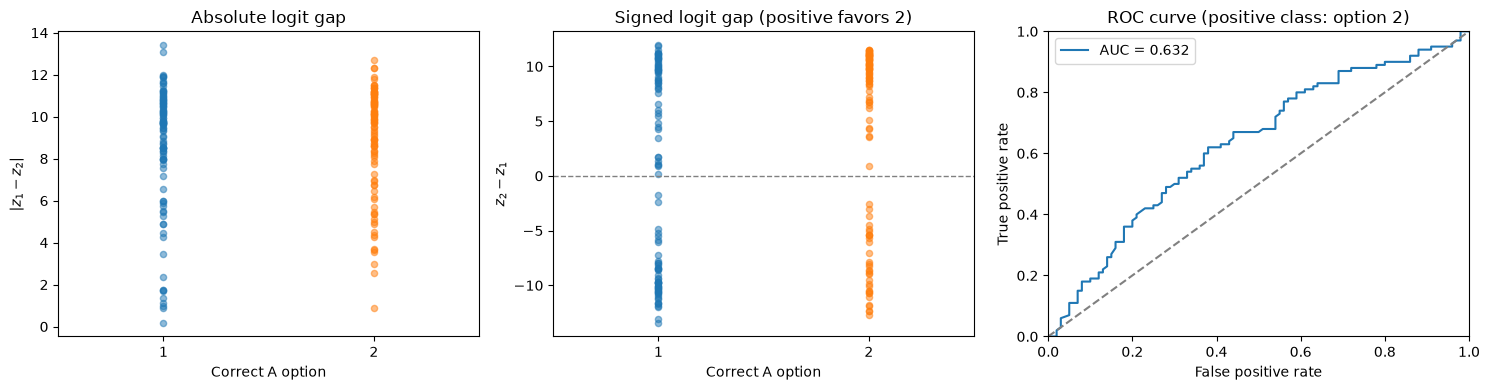

In [30]:
#@title Cell 16: Test logit-gap plots and ROC AUC
# Run Cell 15 first. Reuses all test results without another model pass.
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

labels = logit_gaps["correct_option"].to_numpy()
delta = logit_gaps["signed_gap"].to_numpy()  # z2 - z1
auc = roc_auc_score(labels == 2, delta)
print(f"ROC AUC: {auc:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title, ylabel in zip(
    axes[:2], ["absolute_gap", "signed_gap"],
    ["Absolute logit gap", "Signed logit gap (positive favors 2)"],
    [r"$|z_1 - z_2|$", r"$z_2 - z_1$"],
):
    for option in (1, 2):
        values = logit_gaps.loc[labels == option, column]
        ax.scatter([option] * len(values), values, alpha=0.5, s=20)
    ax.set(title=title, xlabel="Correct A option", ylabel=ylabel, xlim=(0.5, 2.5))
    ax.set_xticks([1, 2])
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)

fpr, tpr, _ = roc_curve(labels == 2, delta)
axes[2].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
axes[2].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[2].set(title="ROC curve (positive class: option 2)",
            xlabel="False positive rate", ylabel="True positive rate",
            xlim=(0, 1), ylim=(0, 1))
axes[2].legend()
plt.tight_layout()
plt.show()


In [31]:
model.eval()
s = train_data[0]

prompt = PROMPT_TEMPLATE.format(
    question_A=s["question_A"],
    question_B=s["question_B"],
    choice_1=s["choices"][0],
    choice_2=s["choices"][1],
)

inputs = tokenizer(prompt, return_tensors="pt").to(device)

with torch.inference_mode():
    output = model(
        **inputs,
        output_hidden_states=True,
        logits_to_keep=1,
        use_cache=False
    )

    # Final hidden state, before the output projection
    h = output.hidden_states[-1][0, -1].float()

    # Recompute the two output projection scores in FP32
    head_weights = model.get_output_embeddings().weight[
        choice_ids
    ].float()

    raw_logits = head_weights @ h

    cap = model.config.final_logit_softcapping
    capped_fp32 = raw_logits if cap is None else cap * torch.tanh(raw_logits / cap)

    print("Raw pre-cap logits:", raw_logits.tolist())
    print("Recomputed FP32 logits (current softcap setting):", capped_fp32.tolist())
    print(f"Actual model logits ({output.logits.dtype}):",
          output.logits[0, -1, choice_ids].tolist())

Raw pre-cap logits: [20.685680389404297, 8.998327255249023]
Recomputed FP32 logits (current softcap setting): [17.930259704589844, 8.737846374511719]
Actual model logits (torch.bfloat16): [17.875, 8.8125]
